# CS781 Capstone — Phase 1 (Architecture 3: Hybrid Prefix-LM)
Name: Aditya Kumar | Roll No: 240059 | Email: adityaj24@iitk.ac.in

In [1]:
!pip install ijson --break-system-packages -q
import os, math, json, time, random, zipfile, csv
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from huggingface_hub import login, hf_hub_download

hf_token = os.environ["HF_TOKEN"]
login(token=hf_token)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_GPUS = torch.cuda.device_count()
print(DEVICE, NUM_GPUS)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 3.2 MB/s eta 0:00:00a 0:00:01
cuda 2


In [2]:
SEED = 42
random.seed(SEED); torch.manual_seed(SEED)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
DATA_SOURCES = [
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
]
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

ARCH_NAME = "hybrid_prefix_lm"

BPE_VOCAB_SIZE = 12000
BPE_TRAIN_CHARS = 8000000
MAX_BPE_WORDS = 100000

SRC_LEN = 256
TGT_LEN = 256
BLOCK_SIZE = SRC_LEN + TGT_LEN

TRAIN_TOKENS = 300000000
VAL_TOKENS = 10000000
BATCH_SIZE = 16
GRAD_ACCUM_STEPS = 4
TRAIN_STEPS = 13800
EVAL_EVERY = 500
WARMUP_STEPS = 200
LR = 3e-4
WEIGHT_DECAY = 0.1

D_MODEL = 768
N_LAYERS = 14
N_HEADS = 12
D_FF = 3072
DROPOUT = 0.1

TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 400
TEMPERATURE = 0.8
TOP_P = 0.95
CHECKPOINT_EVERY = 250

_data_tag = "-".join(s.split("/")[-1].replace(".json", "") for s in DATA_SOURCES)
RUN_ID = f"{ARCH_NAME}_{_data_tag}"
OUTPUT_DIR = f"/kaggle/working/cs781_phase1/{RUN_ID}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

SHARED_DIR = "/kaggle/working/cs781_phase1/_shared"
os.makedirs(SHARED_DIR, exist_ok=True)
TOKENIZER_PATH = os.path.join(SHARED_DIR, "bpe_tokenizer.json")
TOKENIZED_CACHE_PATH = os.path.join(SHARED_DIR, "tokenized_corpus.pt")
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "checkpoint.pt")
MODEL_PATH = os.path.join(OUTPUT_DIR, "model.pt")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss.png")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
HELDOUT_TRUTH_PATH = os.path.join(OUTPUT_DIR, "heldout_truth.json")
HELDOUT_PRED_PATH = os.path.join(OUTPUT_DIR, "heldout_prediction.json")
LOG_PATH = "/kaggle/working/cs781_phase1/experiment_log.csv"
print(RUN_ID)

hybrid_prefix_lm_train_supreme_court-train_acts-train_high_courts-train_tribunals


In [3]:
def download(path):
    return hf_hub_download(repo_id=HF_DATASET_REPO, filename=path, repo_type="dataset", token=hf_token)

train_file_paths = [download(p) for p in DATA_SOURCES]
test_file_path = download(TEST_FILE)

import ijson

CHARS_PER_TOKEN_EST = 6
CHAR_BUDGET = (TRAIN_TOKENS + VAL_TOKENS) * CHARS_PER_TOKEN_EST + BPE_TRAIN_CHARS + 5000000
MIN_RECORDS = 1000

def stream_records(path, char_budget, min_records):
    collected_chars, n = 0, 0
    with open(path, "rb") as f:
        for rec in ijson.items(f, "item"):
            yield rec
            collected_chars += len(rec.get("text", ""))
            n += 1
            if collected_chars >= char_budget and n >= min_records:
                return

per_file_budget = CHAR_BUDGET // len(train_file_paths)
per_file_min = max(MIN_RECORDS // len(train_file_paths), 300)

records = []
for p in train_file_paths:
    records.extend(stream_records(p, per_file_budget, per_file_min))

random.Random(SEED).shuffle(records)

N_HELDOUT_DOCS = 200
heldout_records = records[-N_HELDOUT_DOCS:]
train_pool_records = records[:-N_HELDOUT_DOCS]
full_train_text = "\n".join(r["text"] for r in train_pool_records)
print(len(records), len(full_train_text))

Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_acts.jso(…):   0%|          | 0.00/729M [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_high_cou(…):   0%|          | 0.00/10.7G [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_tribunal(…):   0%|          | 0.00/6.48G [00:00<?, ?B/s]

test.json: 0.00B [00:00, ?B/s]

261738 1872052005


In [4]:
class ByteLevelBPETokenizer:
    SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]

    def __init__(self):
        self.merges = {}
        self.id_to_bytes = {i: bytes([i]) for i in range(256)}
        self.special_to_id = {}
        for i, tok in enumerate(self.SPECIAL_TOKENS):
            tid = 256 + i
            self.special_to_id[tok] = tid
            self.id_to_bytes[tid] = tok.encode("utf-8")

    @property
    def vocab_size(self):
        return len(self.id_to_bytes)

    @staticmethod
    def _pair_counts(sequences):
        counts = {}
        for seq, freq in sequences:
            for pair in zip(seq, seq[1:]):
                counts[pair] = counts.get(pair, 0) + freq
        return counts

    @staticmethod
    def _apply_merge(seq, pair, new_id):
        out, i = [], 0
        while i < len(seq):
            if i < len(seq) - 1 and (seq[i], seq[i + 1]) == pair:
                out.append(new_id); i += 2
            else:
                out.append(seq[i]); i += 1
        return out

    def train(self, text, vocab_size, max_words=MAX_BPE_WORDS, verbose=True):
        num_merges = vocab_size - self.vocab_size
        if num_merges <= 0:
            return self

        word_freq = {}
        for word in text.split():
            word_freq[word] = word_freq.get(word, 0) + 1
        if len(word_freq) > max_words:
            word_freq = dict(sorted(word_freq.items(), key=lambda kv: -kv[1])[:max_words])
        sequences = [[list(word.encode("utf-8")), freq] for word, freq in word_freq.items()]

        next_id = self.vocab_size
        for step in range(num_merges):
            counts = self._pair_counts(sequences)
            if not counts:
                break
            best_pair = max(counts, key=counts.get)
            self.merges[best_pair] = next_id
            self.id_to_bytes[next_id] = self.id_to_bytes[best_pair[0]] + self.id_to_bytes[best_pair[1]]
            for entry in sequences:
                entry[0] = self._apply_merge(entry[0], best_pair, next_id)
            if verbose and (step + 1) % 1000 == 0:
                print(step + 1, next_id + 1)
            next_id += 1
        return self

    def encode(self, text):
        ids = []
        for word in text.split():
            seq = list(word.encode("utf-8"))
            while len(seq) > 1:
                mergeable = [p for p in zip(seq, seq[1:]) if p in self.merges]
                if not mergeable:
                    break
                pair = min(mergeable, key=lambda p: self.merges[p])
                seq = self._apply_merge(seq, pair, self.merges[pair])
            ids.extend(seq)
            ids.append(self.special_to_id["</s>"])
        return ids

    def encode_to_array(self, text, max_tokens):
        arr = np.empty(max_tokens, dtype=np.int32)
        n = 0
        for word in text.split():
            seq = list(word.encode("utf-8"))
            while len(seq) > 1:
                mergeable = [p for p in zip(seq, seq[1:]) if p in self.merges]
                if not mergeable:
                    break
                pair = min(mergeable, key=lambda p: self.merges[p])
                seq = self._apply_merge(seq, pair, self.merges[pair])
            seq.append(self.special_to_id["</s>"])
            for t in seq:
                if n >= max_tokens:
                    return arr[:n]
                arr[n] = t; n += 1
        return arr[:n]

    def decode(self, ids):
        words, current = [], []
        for i in ids:
            if i == self.special_to_id["</s>"]:
                if current:
                    words.append(b"".join(self.id_to_bytes.get(int(t), b"") for t in current).decode("utf-8", errors="ignore"))
                    current = []
            else:
                current.append(i)
        if current:
            words.append(b"".join(self.id_to_bytes.get(int(t), b"") for t in current).decode("utf-8", errors="ignore"))
        return " ".join(words)

    def save(self, path):
        merges_serializable = {f"{a},{b}": nid for (a, b), nid in self.merges.items()}
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"merges": merges_serializable}, f)

    @classmethod
    def load(cls, path):
        tok = cls()
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        for pair_str, nid in data["merges"].items():
            a, b = (int(x) for x in pair_str.split(","))
            tok.merges[(a, b)] = nid
            tok.id_to_bytes[nid] = tok.id_to_bytes[a] + tok.id_to_bytes[b]
        return tok

In [5]:
if os.path.exists(TOKENIZER_PATH):
    tokenizer = ByteLevelBPETokenizer.load(TOKENIZER_PATH)
else:
    tokenizer = ByteLevelBPETokenizer().train(full_train_text[:BPE_TRAIN_CHARS], BPE_VOCAB_SIZE)
    tokenizer.save(TOKENIZER_PATH)

VOCAB_SIZE = tokenizer.vocab_size
print(VOCAB_SIZE)

12000


In [6]:
def to_tensor(x):
    return torch.from_numpy(x) if isinstance(x, np.ndarray) else x

if os.path.exists(TOKENIZED_CACHE_PATH):
    cache = torch.load(TOKENIZED_CACHE_PATH, weights_only=False)
    train_ids = to_tensor(cache["train_ids"])
    val_ids = to_tensor(cache["val_ids"])
else:
    all_ids = tokenizer.encode_to_array(full_train_text, TRAIN_TOKENS + VAL_TOKENS)
    split = int(len(all_ids) * (TRAIN_TOKENS / (TRAIN_TOKENS + VAL_TOKENS)))
    train_ids = torch.from_numpy(all_ids[:split].astype(np.int64, copy=True))
    val_ids = torch.from_numpy(all_ids[split:].astype(np.int64, copy=True))
    torch.save({"train_ids": train_ids, "val_ids": val_ids}, TOKENIZED_CACHE_PATH)

del full_train_text
print(len(train_ids), len(val_ids))

def make_blocks(ids, block_size):
    n = (len(ids) // block_size) * block_size
    return ids[:n].clone().view(-1, block_size)

train_blocks = make_blocks(train_ids, BLOCK_SIZE)
val_blocks = make_blocks(val_ids, BLOCK_SIZE)

LOSS_MASK = (torch.arange(BLOCK_SIZE - 1) + 1 >= SRC_LEN).float()

class PrefixBlockDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = blocks
    def __len__(self):
        return len(self.blocks)
    def __getitem__(self, idx):
        x = self.blocks[idx]
        return x[:-1], x[1:]

train_loader = DataLoader(PrefixBlockDataset(train_blocks), batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(PrefixBlockDataset(val_blocks), batch_size=BATCH_SIZE, shuffle=False, drop_last=True)

300000000 10000000


In [7]:
def split_prompt_continuation(text, prompt_words=512, cont_words=128):
    words = text.split()
    if len(words) < prompt_words + 20:
        return None
    return " ".join(words[:prompt_words]), " ".join(words[prompt_words: prompt_words + cont_words])

heldout_truth, heldout_prompts = {}, {}
for i, rec in enumerate(heldout_records):
    r = split_prompt_continuation(rec["text"])
    if r is None:
        continue
    ex_id = str(i + 1)
    heldout_prompts[ex_id] = {"text": r[0]}
    heldout_truth[ex_id] = {"text": r[1]}

with open(HELDOUT_TRUTH_PATH, "w", encoding="utf-8") as f:
    json.dump(heldout_truth, f, ensure_ascii=False, indent=2)
print(len(heldout_truth))

74


In [8]:
class PrefixAwareAttention(nn.Module):
    """Bidirectional attention within the prefix and causal attention after it."""
    def __init__(self, d_model, n_heads, max_seq_len, dropout=0.0):
        super().__init__()
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.scale = 1.0 / math.sqrt(self.d_head)
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        causal = torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool))
        self.register_buffer("causal_mask", causal, persistent=False)

    def forward(self, x, prefix_len):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)

        pos = torch.arange(T, device=x.device)
        in_prefix = pos < prefix_len
        prefix_bonus = in_prefix.unsqueeze(1) & in_prefix.unsqueeze(0)
        allowed = self.causal_mask[:T, :T] | prefix_bonus

        scores = torch.matmul(q, k.transpose(-2, -1)) * self.scale
        scores = scores.masked_fill(~allowed, float("-inf"))
        attn = self.attn_dropout(torch.softmax(scores, dim=-1))
        out = torch.matmul(attn, v).transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.out_proj(out))


def sinusoidal_positional_encoding(max_len, d_model):
    pe = torch.zeros(max_len, d_model)
    position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    return pe


class PrefixLMBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, max_seq_len, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = PrefixAwareAttention(d_model, n_heads, max_seq_len, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model), nn.Dropout(dropout))

    def forward(self, x, prefix_len):
        x = x + self.attn(self.ln1(x), prefix_len)
        x = x + self.ff(self.ln2(x))
        return x


class PrefixLM(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_heads, d_ff, max_seq_len, dropout=0.1):
        super().__init__()
        self.max_seq_len = max_seq_len
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.register_buffer("pos_emb", sinusoidal_positional_encoding(max_seq_len, d_model), persistent=False)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([PrefixLMBlock(d_model, n_heads, d_ff, max_seq_len, dropout) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.token_emb.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, idx, prefix_len, targets=None, loss_mask=None):
        B, T = idx.shape
        x = self.drop(self.token_emb(idx) + self.pos_emb[:T].unsqueeze(0))
        for block in self.blocks:
            x = block(x, prefix_len)
        logits = self.lm_head(self.ln_f(x))
        loss = None
        if targets is not None:
            per_tok = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.reshape(-1), reduction="none").view(B, T)
            m = (torch.arange(T, device=idx.device) + 1 >= prefix_len).to(per_tok.dtype)
            loss = (per_tok * m).sum() / (m.sum() * B).clamp(min=1.0)
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, prefix_len, max_new_tokens, temperature=1.0, top_p=0.95):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.max_seq_len:]
            logits, _ = self(idx_cond, prefix_len=min(prefix_len, idx_cond.shape[1]))
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            probs = torch.softmax(logits, dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True, dim=-1)
            cum_probs = torch.cumsum(sorted_probs, dim=-1)
            cutoff = (cum_probs > top_p).float().argmax(dim=-1, keepdim=True)
            mask = torch.arange(sorted_probs.size(-1), device=idx.device).unsqueeze(0) > cutoff
            sorted_probs = sorted_probs.masked_fill(mask, 0.0)
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            next_sorted = torch.multinomial(sorted_probs, num_samples=1)
            next_token = torch.gather(sorted_idx, -1, next_sorted)
            idx = torch.cat([idx, next_token], dim=1)
        return idx

In [9]:
def build_model(arch_name):
    if arch_name == "hybrid_prefix_lm":
        return PrefixLM(VOCAB_SIZE, D_MODEL, N_LAYERS, N_HEADS, D_FF, BLOCK_SIZE, DROPOUT)
    raise ValueError(arch_name)

raw_model = build_model(ARCH_NAME).to(DEVICE)
n_params = sum(p.numel() for p in raw_model.parameters())
print(n_params / 1e6)
assert 50e6 <= n_params <= 300e6

if NUM_GPUS > 1:
    model = nn.DataParallel(raw_model)
else:
    model = raw_model

108.404736


In [10]:
!df -h /kaggle/working
!rm -f /kaggle/working/cs781_phase1/*/checkpoint.pt.tmp
!rm -f /kaggle/working/cs781_phase1/*/tokenized_corpus.pt
!rm -rf /root/.cache/huggingface /kaggle/working/.cache

Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G   15G  4.8G  76% /kaggle/working


In [11]:
def get_lr(step, total_steps, warmup_steps, base_lr):
    if step < warmup_steps:
        return base_lr * step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * base_lr * (1 + math.cos(math.pi * progress))

def evaluate(loader, max_batches=50):
    model.eval()
    losses = []
    loss_mask = LOSS_MASK.to(DEVICE)
    with torch.no_grad():
        for i, (x, y) in enumerate(loader):
            if i >= max_batches:
                break
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                _, loss = model(x, prefix_len=SRC_LEN, targets=y, loss_mask=loss_mask)
                loss = loss.mean()
            losses.append(loss.item())
    model.train()
    return sum(losses) / max(1, len(losses))

def save_checkpoint(path, step, train_loss_history, val_loss_history, step_history, elapsed_seconds):
    tmp_path = path + ".tmp"
    if os.path.exists(tmp_path):
        os.remove(tmp_path)
    free = shutil.disk_usage(os.path.dirname(path)).free
    if free < 2.5 * 2**30:
        raise RuntimeError(f"Only {free/2**30:.1f} GB free - clear disk space first")
    torch.save({
        "step": step, "model_state": raw_model.state_dict(), "optimizer_state": optimizer.state_dict(),
        "scaler_state": scaler.state_dict(), "train_loss_history": train_loss_history,
        "val_loss_history": val_loss_history, "step_history": step_history, "elapsed_seconds": elapsed_seconds,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "python_rng_state": random.getstate(),
        "run_config": {"ARCH_NAME": ARCH_NAME, "D_MODEL": D_MODEL, "N_LAYERS": N_LAYERS, "N_HEADS": N_HEADS,
                       "D_FF": D_FF, "BLOCK_SIZE": BLOCK_SIZE, "VOCAB_SIZE": VOCAB_SIZE},
    }, tmp_path)
    os.replace(tmp_path, path)

def load_checkpoint(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    cfg = ckpt["run_config"]
    mismatches = [k for k, v in cfg.items() if str(v) != str(globals()[k])]
    if mismatches:
        raise ValueError(mismatches)
    raw_model.load_state_dict(ckpt["model_state"])
    optimizer.load_state_dict(ckpt["optimizer_state"])
    scaler.load_state_dict(ckpt["scaler_state"])
    torch.set_rng_state(ckpt["torch_rng_state"])
    if ckpt["cuda_rng_state"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(ckpt["cuda_rng_state"])
    random.setstate(ckpt["python_rng_state"])
    return ckpt["step"], ckpt["train_loss_history"], ckpt["val_loss_history"], ckpt["step_history"], ckpt["elapsed_seconds"]


optimizer = torch.optim.AdamW(raw_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY, betas=(0.9, 0.95))
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

if os.path.exists(CHECKPOINT_PATH):
    step, train_loss_history, val_loss_history, step_history, prev_elapsed = load_checkpoint(CHECKPOINT_PATH)
else:
    step, train_loss_history, val_loss_history, step_history, prev_elapsed = 0, [], [], [], 0.0

t0 = time.time()
model.train()
def batch_iterator(loader):
    while True:
        for batch in loader:
            yield batch

data_iter = batch_iterator(train_loader)
loss_mask_device = LOSS_MASK.to(DEVICE)

while step < TRAIN_STEPS:
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    for _ in range(GRAD_ACCUM_STEPS):
        x, y = next(data_iter)
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
            _, loss = model(x, prefix_len=SRC_LEN, targets=y, loss_mask=loss_mask_device)
            loss = loss.mean() / GRAD_ACCUM_STEPS
        scaler.scale(loss).backward()
        accum_loss += loss.item()

    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(raw_model.parameters(), 1.0)
    lr_now = get_lr(step, TRAIN_STEPS, WARMUP_STEPS, LR)
    for g in optimizer.param_groups:
        g["lr"] = lr_now
    scaler.step(optimizer)
    scaler.update()
    step += 1

    if step % 50 == 0:
        train_loss_history.append(accum_loss); step_history.append(step)
        print(step, accum_loss, lr_now)

    if step % EVAL_EVERY == 0 or step == TRAIN_STEPS:
        v_loss = evaluate(val_loader)
        val_loss_history.append((step, v_loss))
        print("eval", step, v_loss, math.exp(v_loss))

    if step % CHECKPOINT_EVERY == 0 or step == TRAIN_STEPS:
        elapsed = prev_elapsed + (time.time() - t0)
        save_checkpoint(CHECKPOINT_PATH, step, train_loss_history, val_loss_history, step_history, elapsed)

training_time = prev_elapsed + (time.time() - t0)
print(training_time / 3600)

8.618273817102114


In [12]:
import shutil
save_checkpoint(CHECKPOINT_PATH, step, train_loss_history, val_loss_history, step_history, prev_elapsed + (time.time() - t0))
print("saved at step", step)

saved at step 13800


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


1.748700852394104 5.7471314518786025


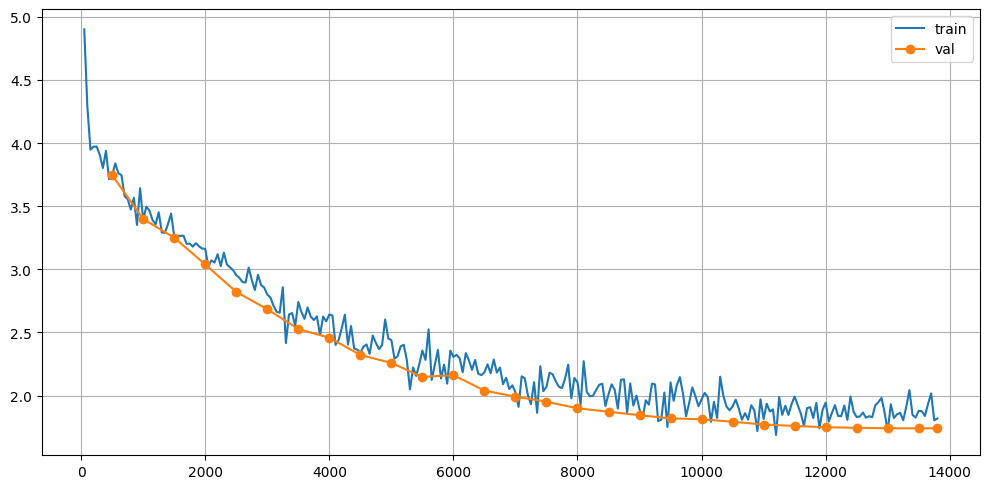

In [13]:
import matplotlib.pyplot as plt

final_val_loss = evaluate(val_loader, max_batches=200)
final_val_ppl = math.exp(final_val_loss)
print(final_val_loss, final_val_ppl)

plt.figure(figsize=(10, 5))
plt.plot(step_history, train_loss_history, label="train")
if val_loss_history:
    vs, vl = zip(*val_loss_history)
    plt.plot(vs, vl, label="val", marker="o")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

In [14]:
torch.save({
    "state_dict": raw_model.state_dict(),
    "config": {"vocab_size": VOCAB_SIZE, "d_model": D_MODEL, "n_layers": N_LAYERS, "n_heads": N_HEADS,
               "d_ff": D_FF, "max_seq_len": BLOCK_SIZE, "dropout": DROPOUT, "arch_name": ARCH_NAME},
}, MODEL_PATH)

In [15]:
def trim_to_words(text, n_words):
    return " ".join(text.split()[:n_words])

def generate_continuation(prompt_text, max_new_tokens=MAX_GENERATION_TOKENS):
    prompt_ids = tokenizer.encode(prompt_text)[-(BLOCK_SIZE - max_new_tokens):]
    idx = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)
    out = raw_model.generate(idx, prefix_len=len(prompt_ids), max_new_tokens=max_new_tokens,
                              temperature=TEMPERATURE, top_p=TOP_P)
    new_text = tokenizer.decode(out[0, len(prompt_ids):].tolist())
    return trim_to_words(new_text, TARGET_GENERATION_WORDS)

def generate_for_dataset(prompt_dict):
    predictions = {}
    for i, (ex_id, rec) in enumerate(prompt_dict.items()):
        predictions[ex_id] = {"text": generate_continuation(rec["text"])}
        if (i + 1) % 25 == 0:
            print(i + 1, len(prompt_dict))
    return predictions

raw_model.eval()

PrefixLM(
  (token_emb): Embedding(12000, 768)
  (drop): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-13): 14 x PrefixLMBlock(
      (ln1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (attn): PrefixAwareAttention(
        (q_proj): Linear(in_features=768, out_features=768, bias=False)
        (k_proj): Linear(in_features=768, out_features=768, bias=False)
        (v_proj): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=False)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (ff): Sequential(
        (0): Linear(in_features=768, out_features=3072, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=3072, out_features=768, bias=True)
        (3): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (ln_f): LayerNorm((76

In [16]:
heldout_preds = generate_for_dataset(heldout_prompts)
with open(HELDOUT_PRED_PATH, "w", encoding="utf-8") as f:
    json.dump(heldout_preds, f, ensure_ascii=False, indent=2)

25 74
50 74


In [17]:
!pip install bert-score --break-system-packages -q
!python /kaggle/input/datasets/adityakumar344/evaluate-phase1-script/evaluate_phase1.py --truth {HELDOUT_TRUTH_PATH} --prediction {HELDOUT_PRED_PATH}

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 1.9 MB/s eta 0:00:00
config.json: 100%|█████████████████████████████| 482/482 [00:00<00:00, 1.44MB/s]
tokenizer_config.json: 100%|█████████████████| 25.0/25.0 [00:00<00:00, 96.2kB/s]
vocab.json: 899kB [00:00, 22.1MB/s]
merges.txt: 456kB [00:00, 24.8MB/s]
tokenizer.json: 1.36MB [00:00, 48.3MB/s]
model.safetensors: 100%|████████████████████| 1.42G/1.42G [00:04<00:00, 307MB/s]
Loading weights: 100%|█| 389/389 [00:00<00:00, 1438.04it/s, Materializing param=
RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.d

In [18]:
from huggingface_hub import HfApi, hf_hub_download

REPO = "Exploration-Lab/CS-781-Capstone"
test_files = [p for p in HfApi().list_repo_files(REPO, repo_type="dataset", token=hf_token)
              if p.startswith("Phase_1_Pretraining/Test/") and p.endswith(".json")]
print(test_files)
test_file_path = hf_hub_download(REPO, test_files[0], repo_type="dataset", token=hf_token)
print(test_file_path)

['Phase_1_Pretraining/Test/test.json']


test.json: 0.00B [00:00, ?B/s]

/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


In [ ]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

official_predictions = generate_for_dataset(test_data)
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(official_predictions, f, ensure_ascii=False, indent=2)

25 1000
50 1000
75 1000
100 1000
125 1000
150 1000
175 1000
200 1000
225 1000
250 1000
275 1000
300 1000
325 1000


In [ ]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(PREDICTION_PATH, arcname="prediction.json")
print(SUBMISSION_ZIP)

In [ ]:
def log_run():
    row = {
        "run_id": RUN_ID, "arch": ARCH_NAME, "data_sources": ";".join(DATA_SOURCES),
        "vocab_size": VOCAB_SIZE, "train_tokens": len(train_ids), "src_len": SRC_LEN, "tgt_len": TGT_LEN,
        "d_model": D_MODEL, "n_layers": N_LAYERS, "n_heads": N_HEADS, "d_ff": D_FF,
        "params_M": round(n_params / 1e6, 2), "train_steps": TRAIN_STEPS,
        "final_val_loss": round(final_val_loss, 6), "final_val_ppl": round(final_val_ppl, 4),
        "training_hours": round(training_time / 3600, 3),
    }
    write_header = not os.path.exists(LOG_PATH)
    with open(LOG_PATH, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(row.keys()))
        if write_header:
            writer.writeheader()
        writer.writerow(row)

log_run()